## Week 10: Visualizations


In [2]:
#Import visualization libraries 

import json 
import re 
import matplotlib.pyplot as plt #wordclouds
import pandas as pd
import plotly.express as px
import pydeck as pdk
from IPython.display import HTML, IFrame #displays pydeck visualizations 
from wordcloud import STOPWORDS, WordCloud

## Visualizing Poll data

I've included two files(`house_average_recent.csv` and `senate_average_recent.csv`) which contaisn average polls for senate and house races for the 2026 US election. First we want to load these as a dataframe:

In [3]:
house = pd.read_csv("house_average_recent.csv")
senate = pd.read_csv("senate_average_recent.csv")

house.head()

,id,state,district,dem,rep,margin,polls,latest,days_old
0,AK-1,AK,1,5.8,45.8,-40.1,1,2026-10-30,1
1,AL-2,AL,2,45.0,49.5,-4.5,1,2026-10-25,6
2,AR-2,AR,2,48.0,52.0,-4.0,1,2026-10-14,17
3,AZ-1,AZ,1,49.4,45.0,4.4,1,2026-10-28,3
4,AZ-2,AZ,2,50.0,48.0,2.0,1,2026-10-14,17


In [4]:
senate.head()

,state,dem,rep,margin,polls,latest,days_old
0,AK,48.7,47.1,1.6,2,2026-10-30,2
1,AL,39.5,47.8,-8.3,1,2026-10-24,8
2,AR,39.0,55.0,-16.0,1,2026-10-28,4
3,FL,43.6,49.3,-5.7,7,2026-10-30,2
4,GA,53.9,43.8,10.1,3,2026-10-23,9


In [7]:
len(senate)

29

In [8]:
len(house)

114

In [9]:
#calculate other (100-dem-rep)

senate["other"] = (100 - senate["dem"] - senate["rep"]).clip(lower = 0).round(1)

senate.head()

,state,dem,rep,margin,polls,latest,days_old,other
0,AK,48.7,47.1,1.6,2,2026-10-30,2,4.2
1,AL,39.5,47.8,-8.3,1,2026-10-24,8,12.7
2,AR,39.0,55.0,-16.0,1,2026-10-28,4,6.0
3,FL,43.6,49.3,-5.7,7,2026-10-30,2,7.1
4,GA,53.9,43.8,10.1,3,2026-10-23,9,2.3


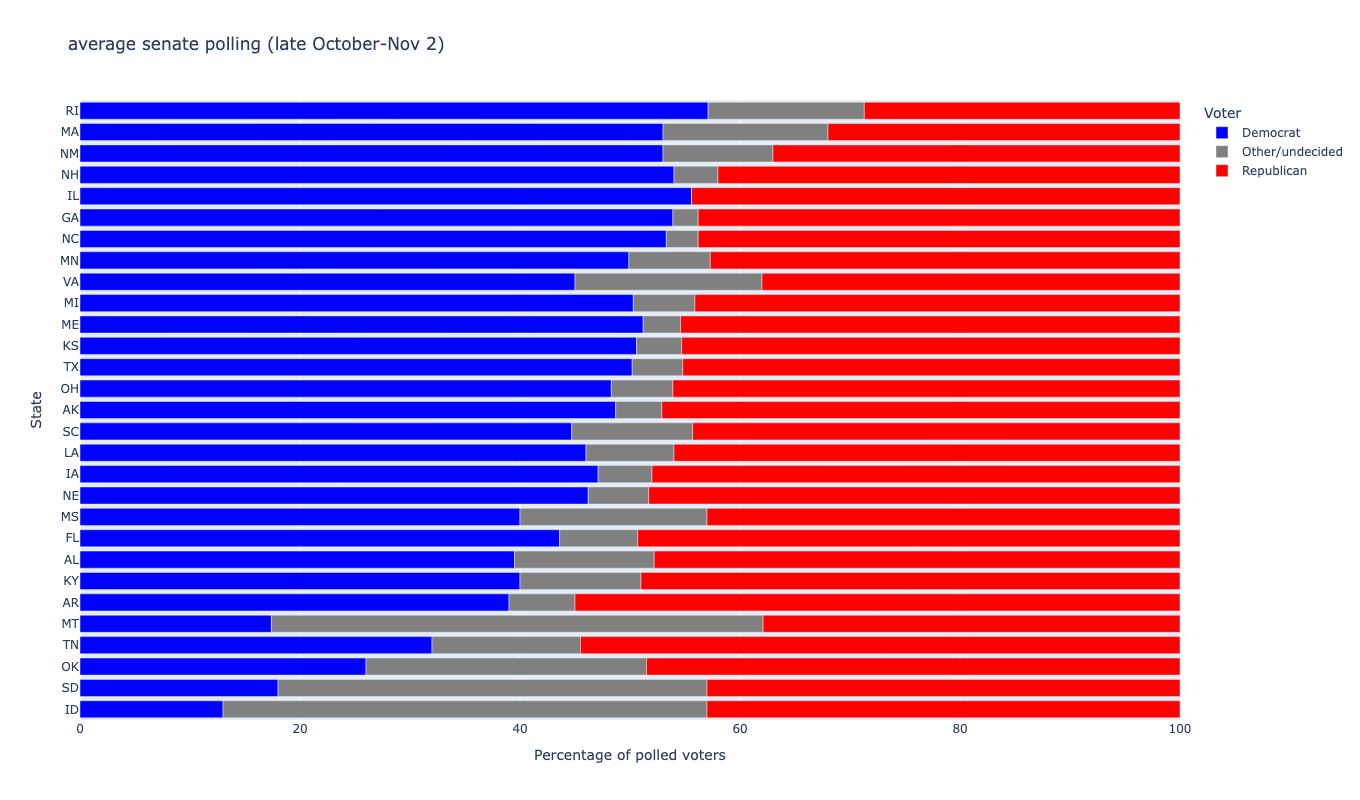

In [18]:
party_names = {"dem": "Democrat", "other": "Other/undecided", "rep": "Republican"}

colors = {"Democrat": "blue", "Other/undecided": "grey", "Republican": "red"}

senate_sorted = senate.sort_values("margin").rename(columns=party_names)

senate_sorted.head()

fig = px.bar(
    senate_sorted, 
    x=["Democrat", "Other/undecided", "Republican"], 
    y="state",
    orientation="h", 
    color_discrete_map=colors, 
    labels={"value": "Percent", "state": "State"},
    hover_data={"polls": True, "latest": True},
    height=800,
    title="average senate polling (late October-Nov 2)"
)

fig.update_layout(
    legend_title_text="Voter",
    xaxis_title = "Percentage of polled voters",
    xaxis_range=[0,100]
)
fig.show()

## Plotting data on a map

We can generate a geographic map using our data. We can combine it with region shapes (states, congressional districts, etc)

Plotly contains US state outlines by default, so we don't need to add them

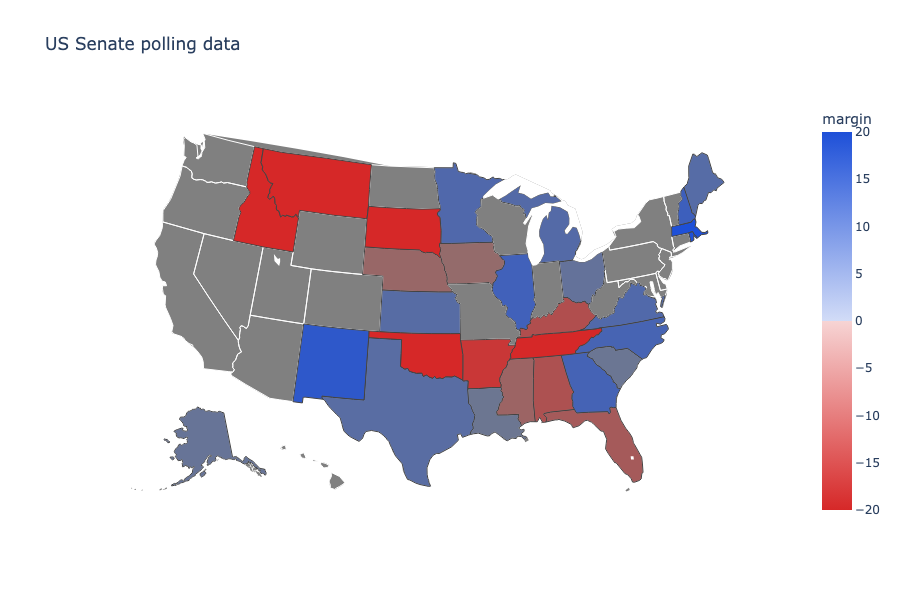

In [25]:
red = "214, 40, 40" #RGB rep of red
blue = "30, 80, 216" #RGB rep of blue

color_scale = [
    [0.0, f"rgba({red}, 1)"], #1 is most opaque for the "a" value of rgba color
    [0.5, f"rgba({red}, 0.2)"], #0.2 means barely opaque,
    [0.5, f"rgba({blue}, 0.2)"],
    [1.0, f"rgba({blue}, 1)"], 
]

colorbar = {
    "title": "Lead by margin", 
    "tickvals": [-20, -10, 0, 10, 20],
    "ticktext": ["R+20", "R+10", "Tie", "D+10", "D+20"],
    
}

fig = px.choropleth(
    senate, 
    locations="state", #This tells the plotly library which column of our data contains locatino information
    locationmode="USA-states", #this tells plotly we are dealing with US state data and to plot
    scope="usa", #zooms in on the US
    color="margin", #give color to each region based on "margin" column of dataset
    color_continuous_scale= color_scale, 
    range_color=[-20,20],
    height=600, 
    title="US Senate polling data"
)

fig.update_geos(landcolor="grey")

fig.show()